In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
os.environ["PATH"] = "/global/common/software/nersc9/texlive/2024/bin/x86_64-linux:" + os.environ["PATH"]

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = "Times New Roman"


150 195 20.319011678313146 0.028563719957522604


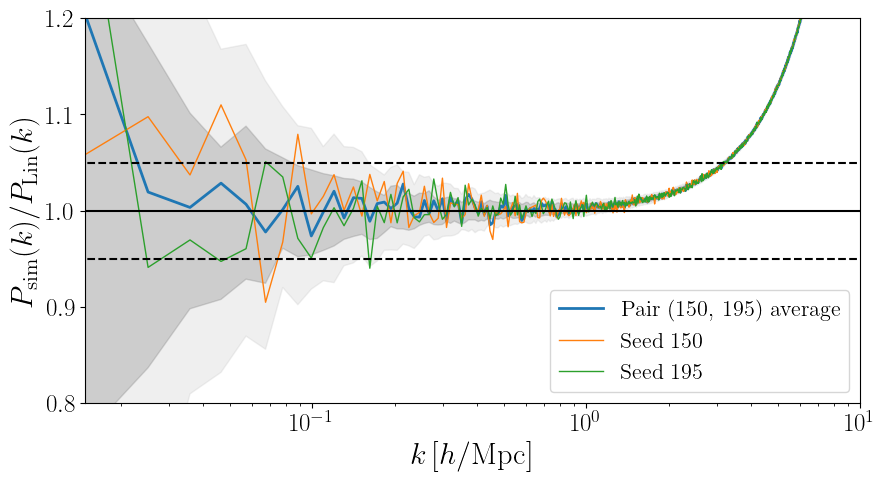

In [3]:
N_seed = 200

# --- Load linear theory P(k) ---
PkLin = np.loadtxt(f'data/m000_matterpower_z{N_seed}.dat')

# Arrays to hold P(k) from simulations
Pk = []
for seed in range(N_seed):
    fname = f'data/pow_{N_seed}/REAL{seed}/output/m000.pk.ini'
    data = np.loadtxt(fname)
    if seed == 0:
        k = data[:, 0]  # store k only once
    Pk.append(data[:, 1])

Pk = np.array(Pk).T  # shape (n_k, N_seed)

# Normalize by linear theory
Pk_norm = Pk / np.interp(k, PkLin[:, 0], PkLin[:, 1])[:, None]

# --- 1σ (68.27%) and 2σ (95.45%) confidence bands ---
Pk_p16 = np.percentile(Pk_norm, 15.865, axis=1)
Pk_p84 = np.percentile(Pk_norm, 84.135, axis=1)

Pk_p2s_low = np.percentile(Pk_norm, 2.275, axis=1)
Pk_p2s_high = np.percentile(Pk_norm, 97.725, axis=1)

fig, ax = plt.subplots(figsize=(10, 5))

# 2σ band first (drawn wider, lighter)
ax.fill_between(
    k, Pk_p2s_low, Pk_p2s_high,
    color=(0.7, 0.7, 0.7), alpha=0.2,
    # label=r"$2\sigma$ scatter"
)

# 1σ band on top (darker)
ax.fill_between(
    k, Pk_p16, Pk_p84,
    color=(0.5, 0.5, 0.5), alpha=0.3,
    # label=r"$1\sigma$ scatter"
)

# --- Pair loop ---
kmax = 20
counter = 0
good_seeds = []  # to store seeds that pass the condition

for seed1 in range(N_seed - 1):
    for seed2 in range(seed1 + 1, N_seed):
        Pk_pair = 0.5 * (Pk[:, seed1] + Pk[:, seed2])
        Pk_pair_norm = Pk_pair / np.interp(k, PkLin[:, 0], PkLin[:, 1])

        d = np.sum(np.abs(Pk_pair_norm[:kmax]))
        e = np.max(np.abs(Pk_pair_norm[1:kmax] - 1))

        if e < 0.03:
            print(seed1, seed2, d, e)
            ax.semilogx(
                k, Pk_pair_norm,
                linewidth=2,
                label=f"Pair ({seed1}, {seed2}) average" if counter == 0 else ""
            )
            counter += 1

            # keep the seeds (stop once we have 2)
            if len(good_seeds) < 2:
                good_seeds.extend([seed1, seed2])

    if len(good_seeds) >= 2:
        break  # stop searching once we got two seeds

# Plot the two good seeds
for idx, seed in enumerate(good_seeds[:2]):
    ax.semilogx(
        k, Pk_norm[:, seed],
        linewidth=1,
        label=f"Seed {seed}"
    )

# Reference lines
ax.plot([0.001, 20], [1.05, 1.05], "k--")
ax.plot([0.001, 20], [0.95, 0.95], "k--")
ax.plot([0.001, 20], [1.0, 1.0], "k-")

# Axis limits
ax.set_xlim(k[0], 10)
ax.set_ylim(0.8, 1.2)

# Tick params and labels
ax.tick_params(axis='x', labelsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.set_xlabel(r"$k \, [h / \mathrm{Mpc}]$", fontsize=22)
ax.set_ylabel(r"$P_{\rm sim}(k)/P_{\rm Lin}(k)$", fontsize=22)

ax.legend(fontsize=16)
plt.savefig("plots/pk_seeds_average.pdf", bbox_inches="tight")
